# Fundamental Drivers

## Research question
How are residual load and renewables associated with prices?

## Data
Source: Bundesnetzagentur | SMARD.de. Observed period: January 2023-18 November 2026; 63,843 native price intervals and 136,128 quarter-hours per core load/wind/solar series. Physical quantities are German net grid/load generation; prices cover DE-LU. Actuals and forecasts remain separate; no missing physical value is replaced by zero.

## Methodology and equations
RL=load-onshore wind-offshore wind-solar, with all components observed in MW. Descriptive quartiles and Pearson/Spearman correlations are supplemented by calendar-controlled Ridge/boosting with a chronological 2025+ holdout. Moving seven-day bootstrap gives descriptive confidence intervals.

In [1]:
from pathlib import Path
import os
import pandas as pd
from IPython.display import Image, display
root = Path.cwd() if Path('reports').exists() else Path.cwd().parent
os.chdir(root)


In [2]:
from power_risk.fundamentals.research import dataset,bins
display(bins(dataset(),'actual_residual_load_mw','price_eur_mwh'))
display(pd.read_csv('reports/quantified_market_findings.csv'))
display(pd.read_csv('reports/fundamental_explanatory_models.csv'))
display(pd.read_csv('reports/feature_importance.csv').sort_values('mae_increase',ascending=False).head(12))

,n,x,mean,median,std
bin,,,,,
"(-15561.591, 16258.65]",6807,7530.669274,25.720612,13.27000,42.466517
"(16258.65, 26099.774]",6806,21521.252529,79.776927,78.28625,31.653088
"(26099.774, 33715.062]",6806,29996.034838,100.844102,95.10000,28.845171
"(33715.062, 41626.552]",6806,37510.558262,116.803571,109.42500,33.118160
"(41626.552, 68275.74]",6807,48962.525851,153.055216,137.28000,64.061640


,finding,variable,outcome,period_start,period_end,complete_rows,low_threshold,high_threshold,low_n,high_n,low_mean,high_mean,difference,ci_low,ci_high,method
0,Residual-load price gradient,actual_residual_load_mw,price_eur_mwh,2022-12-31 23:00:00+00:00,2026-11-18 22:00:00+00:00,34032,19149.0600,39414.1675,8508,8508,34.103580,147.323111,113.219530,106.585446,122.543038,Full-sample descriptive quartiles; 500 moving ...
1,Wind and negative-price incidence,wind_mw,negative,2022-12-31 23:00:00+00:00,2026-11-18 22:00:00+00:00,34032,6503.9575,22810.2500,8508,8508,0.046662,0.072050,0.025388,0.003038,0.047474,Full-sample descriptive quartiles; 500 moving ...
2,Midday solar-price association,actual_solar_mw,price_eur_mwh,2023-01-01 09:00:00+00:00,2026-11-18 14:00:00+00:00,8508,10605.9150,33056.2500,2127,2127,109.393443,21.343619,-88.049824,-100.493046,-76.832867,Full-sample descriptive quartiles; 500 moving ...
3,Demand and high-price incidence,actual_load_mw,spike,2022-12-31 23:00:00+00:00,2026-11-18 22:00:00+00:00,34032,45432.2550,59594.3125,8508,8508,0.004231,0.074753,0.070522,0.043551,0.098125,Full-sample descriptive quartiles; 500 moving ...


,model,holdout_mae,train_rows,holdout_rows
0,calendar_controlled_ridge,32.270822,17544,16488
1,calendar_controlled_boosting,33.980849,17544,16488


,model,feature,mae_increase,repeat_std
0,calendar_controlled_ridge,actual_residual_load_mw,27.315384,0.239368
49,calendar_controlled_boosting,actual_residual_load_mw,18.718836,0.256365
3,calendar_controlled_ridge,actual_gas_mw,1.431629,0.007884
2,calendar_controlled_ridge,actual_solar_mw,1.245892,0.011700
4,calendar_controlled_ridge,actual_hard_coal_mw,0.751038,0.007233
96,calendar_controlled_boosting,month_8,0.256135,0.017614
94,calendar_controlled_boosting,month_6,0.240689,0.027802
45,calendar_controlled_ridge,month_6,0.226285,0.026326
50,calendar_controlled_boosting,wind_mw,0.214087,0.003053
90,calendar_controlled_boosting,month_2,0.207311,0.014252


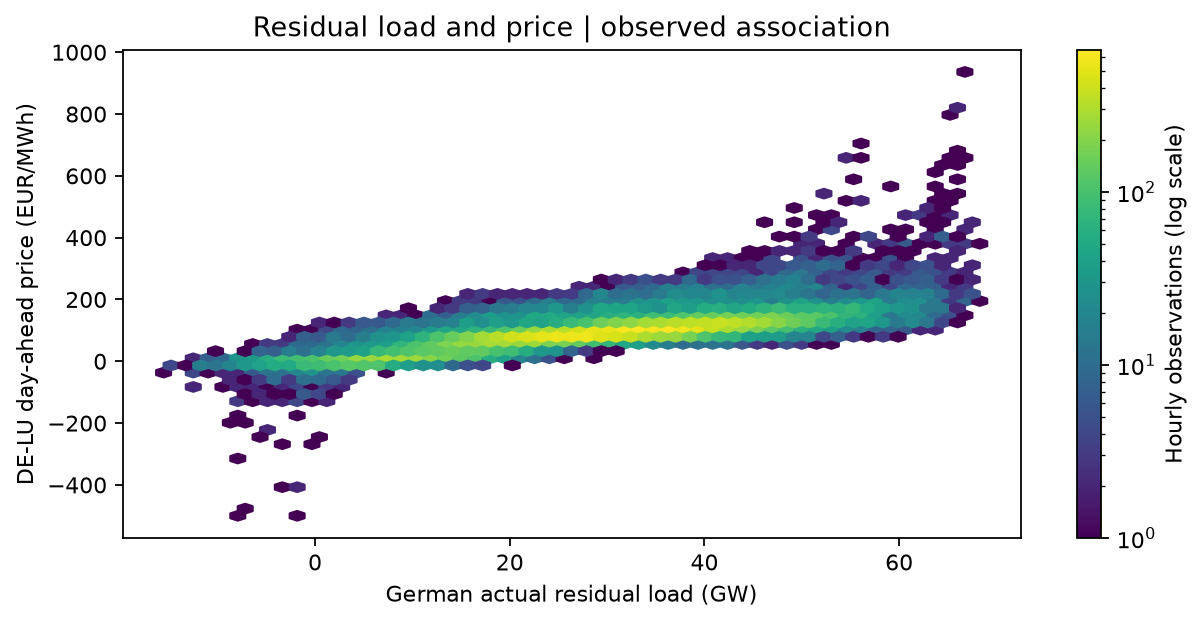

In [3]:
display(Image(filename='reports/residual_load_price_relationship.png'))

## Quantitative findings and commercial interpretation
Upper versus lower residual-load quartiles differ by EUR 113.22/MWh (block CI 106.59-122.54). High-solar midday prices are EUR 88.05/MWh lower. These are consistent with merit-order pressure and renewable price coincidence.

## Limitations
Actual dispatch is endogenous; correlated predictors complicate importance. DE physical quantities differ from DE-LU price-zone totals. Nuclear gaps remain missing. Forecast vintages are unverified.

Calculations call reusable modules; regenerate underlying outputs using the README workflow.